# B1: Research Question

Can the hospital’s first two years of daily revenue help finance staff forecast changes in receipts? The course data dictionary reports revenue in millions of dollars.

I evaluate an autoregressive model against a no-change baseline using two forecast schedules: all predictions issued together and predictions updated each day. A separate model fitted through day 731 projects revenue levels for the next 30 days.

# B2: Objectives And Goals

Estimate daily revenue changes using earlier observations, measure forecast error on later days, and show how uncertainty grows when projecting revenue levels over a month.

# C: Summary Of Assumptions

Time series models operate under several key assumptions that ensure their reliability and accuracy in forecasting. A fundamental assumption is stationarity, which means that the statistical properties of the series, such as mean, variance, and covariance, remain constant over time. Stationary data allows patterns observed in the past to be applied consistently to future periods, and non-stationary data often requires transformations such as differencing or detrending to achieve stability. Another important assumption is autocorrelation, where current values of the series are correlated with past values, creating a dependency structure that enables models like ARIMA to use historical observations for prediction. In addition, many traditional models assume a degree of linearity, meaning that future values are expected to depend on a linear combination of past values and error terms. Finally, time series models typically assume the absence of significant outliers, anomalies, or structural breaks, as these can distort the underlying patterns and reduce the accuracy of forecasts unless explicitly addressed during model development.


In [1]:
#!/usr/bin/env python
# coding: utf-8

# Library Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error


import warnings
warnings.filterwarnings("ignore")

# Importing Dataset
file_path = "../data/hospital_revenue_raw.csv"
df = pd.read_csv(file_path)


# Display df
print(df.shape)
print(df.info())
print(df.head())

(731, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Day      731 non-null    int64  
 1   Revenue  731 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 11.6 KB
None
   Day   Revenue
0    1  0.000000
1    2 -0.292356
2    3 -0.327772
3    4 -0.339987
4    5 -0.124888


In [2]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Handle missing values if any exist
df = df.dropna() 
print(f"Dataset shape after handling missing values: {df.shape}")

# Check for duplicate values
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# Handle duplicate values if any exist
if duplicate_count > 0:
    df = df.drop_duplicates()
    print(f"Dataset shape after removing duplicates: {df.shape}")

Missing values per column:
Day        0
Revenue    0
dtype: int64
Dataset shape after handling missing values: (731, 2)
Number of duplicate rows: 0


# D1: Line Graph Visualization

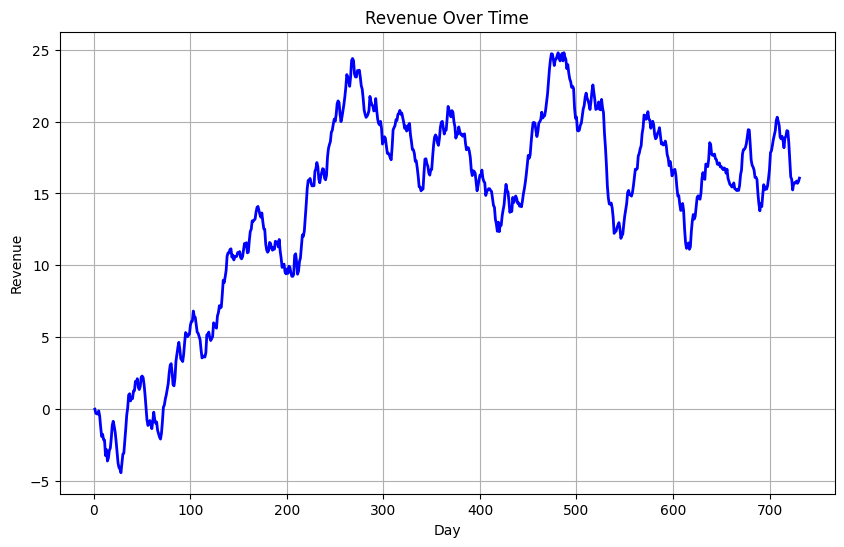

In [3]:
# Line plot of Revenue over Days
plt.figure(figsize=(10,6))
plt.plot(df['Day'], df['Revenue'], color='blue', linewidth=2)

# labels and title
plt.xlabel("Day")
plt.ylabel("Revenue")
plt.title("Revenue Over Time")

# grid
plt.grid(True)

# Show the plot
plt.show()

# D2: Time Step Formatting

The `Day` column runs from 1 through 731 with one observation per day. The pandas row index starts at zero. The plots and the forward forecast below use the day labels from the CSV.

# D3: Stationarity

The Augmented Dickey–Fuller test on revenue levels returned a p-value of 0.1997. At the 5% threshold, the data did not provide enough evidence to reject a unit root. I tested the daily changes next.

In [4]:
# Perform Augmented Dickey-Fuller test
adf_result = adfuller(df['Revenue'])

# Print the results
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

# Interpretation helper
if adf_result[1] <= 0.05:
    print("Reject the unit-root null at the 5% level.")
else:
    print("The data do not reject the unit-root null at the 5% level.")

ADF Statistic: -2.2183190476089485
p-value: 0.19966400615064228
Critical Values:
   1%: -3.4394
   5%: -2.8655
   10%: -2.5689
The data do not reject the unit-root null at the 5% level.


In [5]:
# First-order differencing
df['Revenue_diff'] = df['Revenue'].diff()

# Drop the first NaN created by differencing
df_diff = df['Revenue_diff'].dropna()


adf_result_diff = adfuller(df_diff)

print("ADF Statistic:", adf_result_diff[0])
print("p-value:", adf_result_diff[1])
print("Critical Values:")
for key, value in adf_result_diff[4].items():
    print(f"   {key}: {value:.4f}")

if adf_result_diff[1] <= 0.05:
    print("Reject the unit-root null at the 5% level.")
else:
    print("The data do not reject the unit-root null at the 5% level.")

ADF Statistic: -17.374772303557062
p-value: 5.113206978840171e-30
Critical Values:
   1%: -3.4394
   5%: -2.8655
   10%: -2.5689
Reject the unit-root null at the 5% level.


In [6]:
# Define the split index (80% for training, 20% for testing)
split_index = int(len(df_diff) * 0.8)

# Split into train and test sets
train = df_diff[:split_index]
test = df_diff[split_index:]

# Print shapes
print("Training set length:", len(train))
print("Testing set length:", len(test))

Training set length: 584
Testing set length: 146


# D4: Steps To Prepare The Data

The source contains 731 consecutive daily revenue values with no missing or duplicate rows. First differencing produced 730 changes. The ADF p-value on those changes was approximately 5.11 × 10⁻³⁰. The first 584 changes (days 2–585) form the training period. The following 146 (days 586–731) form the test period.

# D5: Prepared Dataset

In [7]:
# Save the cleaned dataset with differenced series
df.to_csv("cleaned_dataset.csv", index=False)

# Save training and testing sets
train.to_csv("train_dataset.csv", index=True, header=True)
test.to_csv("test_dataset.csv", index=True, header=True)

print("Datasets saved successfully:")
print("- cleaned_dataset.csv")
print("- train_dataset.csv")
print("- test_dataset.csv")


Datasets saved successfully:
- cleaned_dataset.csv
- train_dataset.csv
- test_dataset.csv


# E1: Report Findings and Visualizations

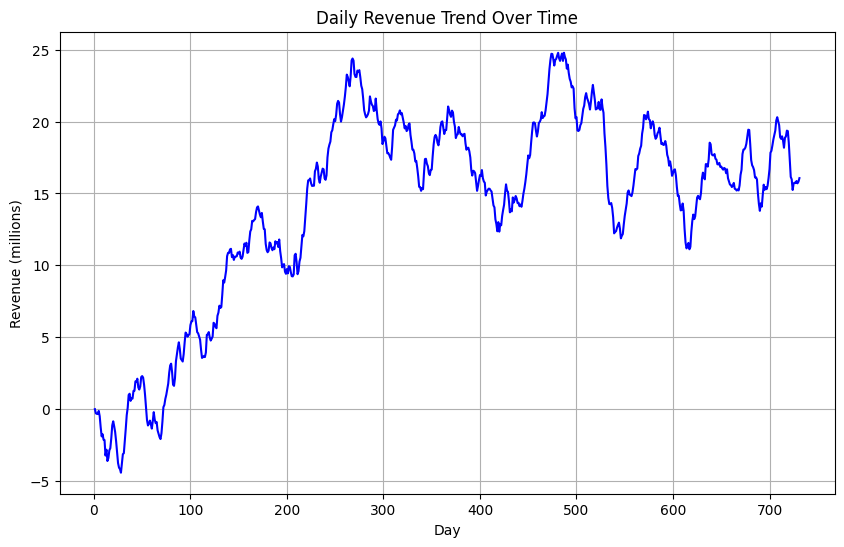

In [8]:
# Trend Visualization

plt.figure(figsize=(10,6))
plt.plot(df['Day'], df['Revenue'], color='blue')
plt.title("Daily Revenue Trend Over Time")
plt.xlabel("Day")
plt.ylabel("Revenue (millions)")
plt.grid(True)
plt.show()


Revenue rises over much of the series and also has periods of decline. Differencing lets the model describe day-to-day movement separately from the changing revenue level.

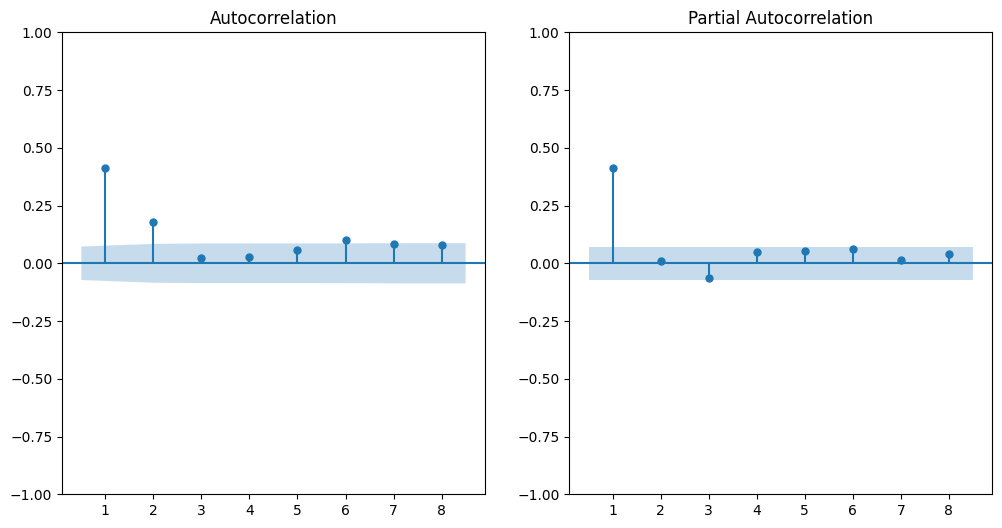

In [9]:
# Autocorrelation & Partial Autocorrelation

plt.figure(figsize=(12, 6))
plt.subplot(121)
plot_acf(df['Revenue_diff'].dropna(), lags=8, zero=False, ax=plt.gca())
plt.subplot(122)
plot_pacf(df['Revenue_diff'].dropna(), lags=8, zero=False, ax=plt.gca())
plt.show()


The ACF plot displays a strong spike at lag 1 followed by a gradual decline, while the PACF plot shows a significant first-lag partial correlation with minimal contributions from higher lags. These patterns indicate short-term dependency within the time series and support the use of an AR(1) structure within the chosen ARIMA model.

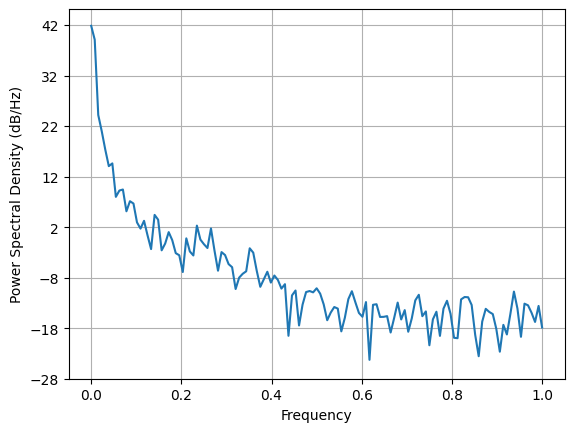

In [10]:
# Spectral Density

plt.psd(x=df.Revenue);

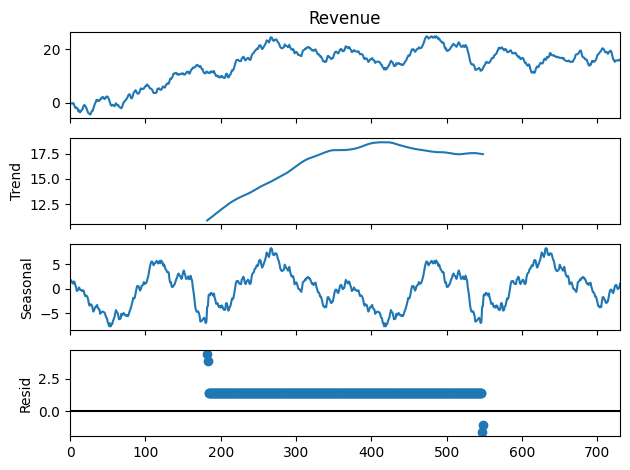

In [11]:
# Seasonal Decomposition

decomposition = seasonal_decompose(df['Revenue'], model='additive', period=365)
decomposition.plot()
plt.show()

The decomposition uses a 365-day period. With about two annual cycles in the file, the seasonal component is exploratory. The forecast below uses one autoregressive lag and has no seasonal term.

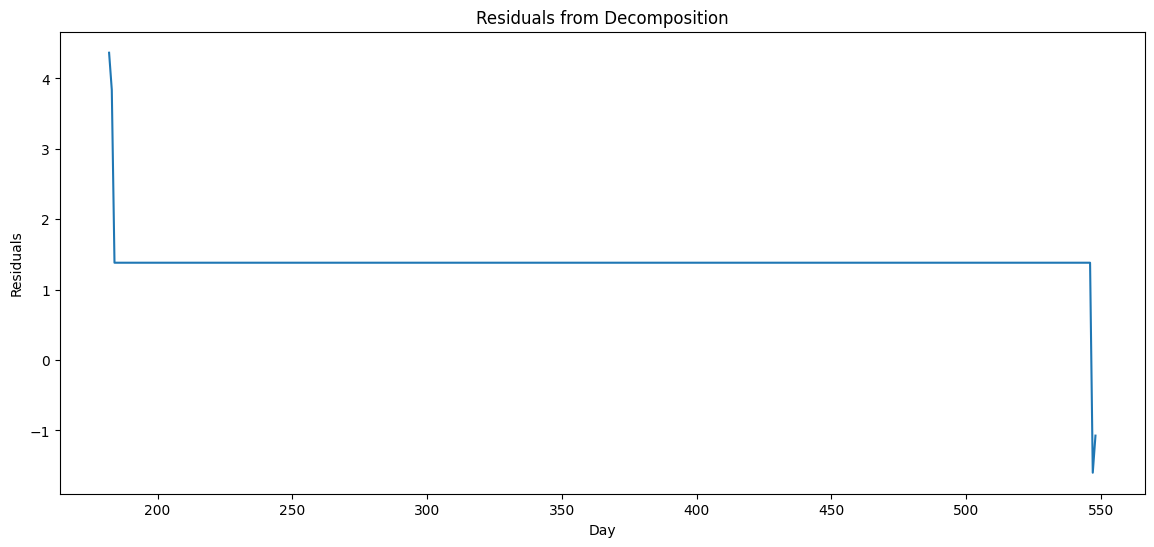

In [12]:
# Residual Analysis

# Residuals from decomposition
residuals = decomposition.resid

# Plot residuals from decomp
plt.figure(figsize = [14,6])
plt.plot(df.index, residuals, label='Residuals')
plt.title('Residuals from Decomposition')
plt.xlabel('Day')
plt.ylabel('Residuals')
plt.show()

This plot shows the residuals from the seasonal decomposition. It can reveal unusually large deviations over time. The ARIMA forecast is evaluated separately on the chronological holdout.

# E2: Arima Model

In [13]:
# ARIMA Model Fitting

# Using the train dataset for the ARIMA model with p=1, d=0, q=0
model = ARIMA(train.reset_index(drop=True), order=(1, 0, 0))
results = model.fit()
print(results.summary())

                               SARIMAX Results                                
Dep. Variable:           Revenue_diff   No. Observations:                  584
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -350.349
Date:                Tue, 03 Nov 2026   AIC                            706.698
Time:                        16:47:19   BIC                            719.808
Sample:                             0   HQIC                           711.808
                                - 584                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0328      0.031      1.063      0.288      -0.028       0.093
ar.L1          0.4079      0.038     10.748      0.000       0.333       0.482
sigma2         0.1943      0.012     15.948      0.0

The lag-one patterns in the ACF and PACF informed the choice of an AR(1) model for daily changes. This is an ARIMA(1,1,0) specification on levels. The exploratory plots used the full series, while the coefficients used in the holdout forecasts were fitted on the first 584 changes.

# E3: Forecasting Daily Changes on the Holdout

In [14]:
# Start at the first step after the training cutoff, then attach the test labels.
forecast = results.get_forecast(steps=len(test))
forecast_mean = pd.Series(
    forecast.predicted_mean.to_numpy(), index=test.index, name="forecast_change"
)
print(forecast_mean)

585    0.071071
586    0.048405
587    0.039159
588    0.035388
589    0.033850
         ...   
726    0.032791
727    0.032791
728    0.032791
729    0.032791
730    0.032791
Name: forecast_change, Length: 146, dtype: float64


In [15]:
# Individual 95% prediction intervals for daily revenue changes.
confidence_intervals = forecast.conf_int(alpha=0.05).set_axis(test.index)
print(confidence_intervals)

     lower Revenue_diff  upper Revenue_diff
585           -0.792856            0.934998
586           -0.884621            0.981430
587           -0.904871            0.983190
588           -0.910461            0.981237
589           -0.912301            0.980001
..                  ...                 ...
726           -0.913421            0.979002
727           -0.913421            0.979002
728           -0.913421            0.979002
729           -0.913421            0.979002
730           -0.913421            0.979002

[146 rows x 2 columns]


# E4: Evaluation on Daily Revenue Changes

The model makes all 146 holdout forecasts from the same training cutoff. MAE measures the average absolute miss and RMSE gives more weight to large misses. Both use millions of dollars of daily revenue change.

In [16]:
rmse = np.sqrt(mean_squared_error(test, forecast_mean))
print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 0.48872356071091366


The RMSE below one million dollars describes errors in the change from one day to the next. A no-change forecast gives the figure a practical point of comparison.

In [17]:
mae = np.mean(np.abs(test - forecast_mean))
baseline_mae = np.mean(np.abs(test))
baseline_rmse = np.sqrt(np.mean(test**2))
print(f"ARIMA MAE: {mae:.4f}, RMSE: {rmse:.4f}")
print(f"No-change MAE: {baseline_mae:.4f}, RMSE: {baseline_rmse:.4f}")

ARIMA MAE: 0.3765, RMSE: 0.4887
No-change MAE: 0.3746, RMSE: 0.4860


# F1: Results

On the 146 test days, the aligned ARIMA forecasts had MAE **0.3765** and RMSE **0.4887** million dollars. Predicting zero daily change gave MAE **0.3746** and RMSE **0.4860** million dollars. The simpler forecast had slightly lower error on both measures in this period.

The fixed-origin evaluation requests exactly 146 steps from the training cutoff and pairs the first with day 586.

# F2: Holdout Forecasts of Daily Revenue Changes

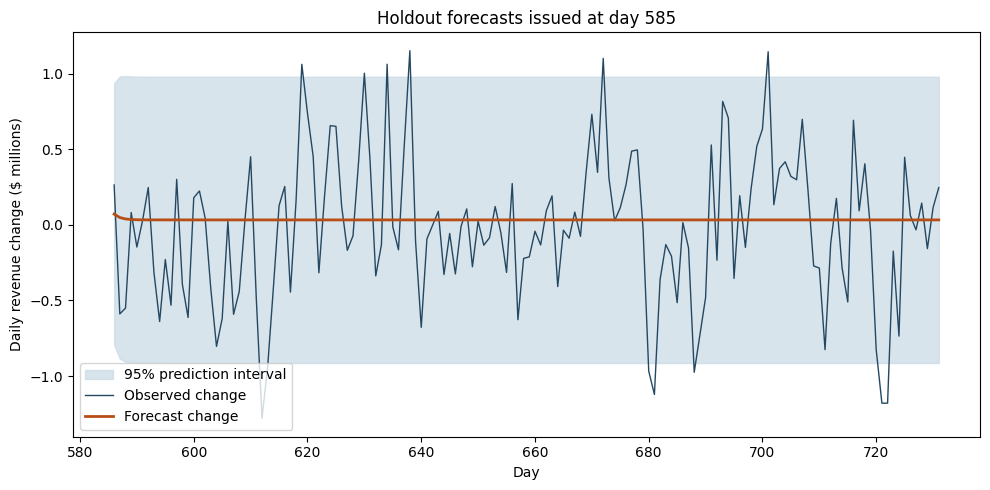

In [18]:
test_days = df.loc[test.index, "Day"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(test_days, confidence_intervals.iloc[:, 0], confidence_intervals.iloc[:, 1],
                color="#c7d9e5", alpha=0.7, label="95% prediction interval")
ax.plot(test_days, test, color="#244862", linewidth=1, label="Observed change")
ax.plot(test_days, forecast_mean, color="#b74e16", linewidth=2, label="Forecast change")
ax.set(xlabel="Day", ylabel="Daily revenue change ($ millions)",
       title="Holdout forecasts issued at day 585")
ax.legend()
fig.tight_layout()
plt.show()

The shaded range applies to each individual daily change. The observations and forecasts shown here are the same 146 pairs used for both error measures.

## 30-day revenue forecast after day 731

An integrated AR(1) model fitted through the last observation forecasts revenue levels and their uncertainty together.

In [19]:
# Refit through the final observed day before issuing a future forecast.
# The linear trend on levels supplies a constant drift after differencing.
level_model = ARIMA(df["Revenue"], order=(1, 1, 0), trend="t").fit()
horizon = 30
future = level_model.get_forecast(steps=horizon).summary_frame(alpha=0.05)
future = future[["mean", "mean_ci_lower", "mean_ci_upper"]].copy()
future.columns = ["forecast", "lower_95", "upper_95"]
last_day = int(df["Day"].iloc[-1])
future.index = pd.RangeIndex(last_day + 1, last_day + horizon + 1, name="Day")
print(future.round(3).to_string())

     forecast  lower_95  upper_95
Day                              
732    16.184    15.320    17.048
733    16.244    14.749    17.739
734    16.282    14.256    18.308
735    16.311    13.831    18.790
736    16.335    13.461    19.209
737    16.358    13.133    19.583
738    16.381    12.837    19.924
739    16.403    12.566    20.239
740    16.425    12.316    20.534
741    16.447    12.082    20.811
742    16.469    11.863    21.074
743    16.491    11.656    21.325
744    16.512    11.459    21.566
745    16.534    11.271    21.798
746    16.556    11.091    22.022
747    16.578    10.918    22.238
748    16.600    10.752    22.448
749    16.622    10.592    22.652
750    16.644    10.437    22.851
751    16.666    10.287    23.045
752    16.688    10.141    23.234
753    16.710    10.000    23.420
754    16.732     9.862    23.601
755    16.754     9.728    23.779
756    16.775     9.598    23.953
757    16.797     9.471    24.124
758    16.819     9.346    24.292
759    16.841 

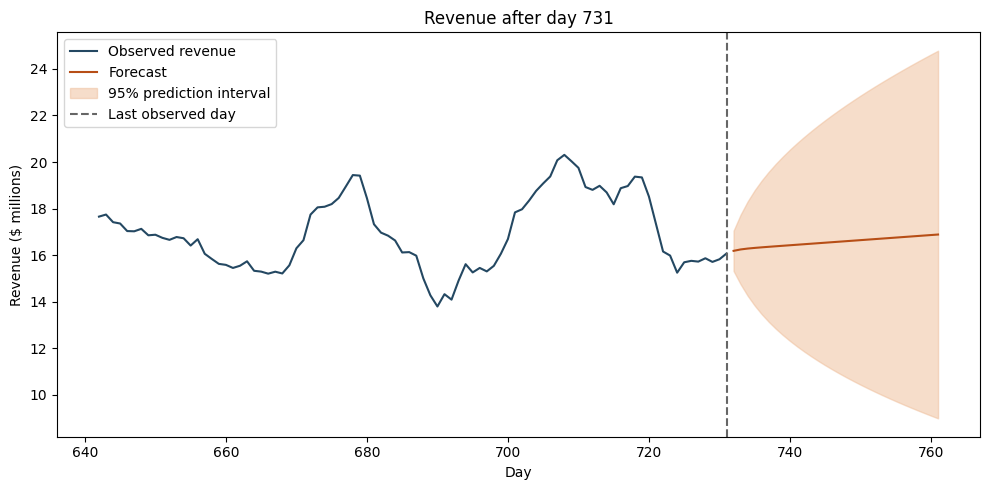

In [20]:
recent = df.tail(90)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(recent["Day"], recent["Revenue"], label="Observed revenue", color="#244862")
ax.plot(future.index, future["forecast"], label="Forecast", color="#b74e16")
ax.fill_between(future.index, future["lower_95"], future["upper_95"],
                color="#eebc97", alpha=0.5, label="95% prediction interval")
ax.axvline(last_day, color="#666666", linestyle="--", label="Last observed day")
ax.set(xlabel="Day", ylabel="Revenue ($ millions)", title="Revenue after day 731")
ax.legend()
fig.tight_layout()
plt.show()

This forecast uses all 731 observed revenue levels. The underlying model allows daily changes to depend on the previous change and includes drift. The shaded bounds come directly from the fitted model’s forecast on the revenue level. Days 732–761 have no observed outcomes in this dataset.

## Forecasts updated each day

The earlier holdout issues 146 forecasts together at day 585. This additional evaluation predicts each next day after refitting on all changes observed so far. Its first fit ends at day 585 and its last at day 730. Both evaluations use days 586–731. The no-change forecast is zero daily change in either setting.

Verified environment: Python 3.13.1, numpy 2.2.2, pandas 2.2.3, scipy 1.15.2, scikit-learn 1.6.1, statsmodels 0.14.4, matplotlib 3.10.0, seaborn 0.13.2. The expanding window does not repeat model-family selection.

In [ ]:
import numpy as np
# Expanding-window one-day evaluation: no future observations enter a fit.
rolling_predictions = []
history_changes = df['Revenue'].diff().dropna().reset_index(drop=True)
for offset in range(146):
    history = history_changes.iloc[:584 + offset]
    daily_model = ARIMA(history, order=(1, 0, 0)).fit()
    rolling_predictions.append(float(np.asarray(daily_model.forecast(steps=1))[0]))
rolling_actual = history_changes.iloc[584:].to_numpy()
rolling_mae = float(np.mean(np.abs(rolling_actual - np.asarray(rolling_predictions))))
rolling_rmse = float(np.sqrt(np.mean((rolling_actual - np.asarray(rolling_predictions)) ** 2)))
print(f'Rolling one-day MAE: {rolling_mae:.10f}')
print(f'Rolling one-day RMSE: {rolling_rmse:.10f}')


Rolling one-day MAE: 0.3531405970
Rolling one-day RMSE: 0.4407629180


For daily updated forecasts, ARIMA had MAE **0.3531** and RMSE **0.4408** million dollars, lower than the no-change baseline (**0.3746**, **0.4860**). For the one-batch evaluation at day 585, no-change performed slightly better. Forecast horizon and update frequency change the operational conclusion. These results measure daily changes on one holdout, not errors in monthly budget totals.

# F3: Recommendations

Choose an evaluation that matches the planning cadence. Updating the ARIMA forecast each day improved accuracy over no change on these test days; the single batch issued at day 585 did not. Before using the 30-day projection for budgeting, evaluate daily levels and monthly totals at multiple historical cutoffs. Revenue alone cannot explain why receipts changed.

# G: Reporting

This notebook includes data preparation, model fitting, chronological holdout evaluation, a daily-refit comparison and a separate 30-day revenue-level projection. Each chart identifies the forecast origin and scale.

# H: Sources For Third-Party Code

No external web sources or third-party data were used in this analysis. The dataset (hospital_revenue_raw.csv) was provided as part of the course materials, and all analysis and visualizations were generated solely within the Jupyter Notebook environment using standard Python libraries.

# I: Sources

No external references, code segments, or written materials were quoted, paraphrased, or summarized in this submission. All content, including code and narrative explanations, was original and created for the purpose of completing this project.